In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

from src.bandit.simulator import simulate_bandit_horizon, summarize_bandit_results
from src.data.loader import ingest_hillstrom, load_config, stratified_split
from src.models.optimizer import budget_frontier, optimize_binary_policy
from src.models.uplift import UpliftModelWrapper

cfg = load_config("config/hillstrom.yaml")
processed_path = Path(cfg["processed_path"])
df = pl.read_parquet(processed_path) if processed_path.exists() else ingest_hillstrom(cfg)

train_df, cal_df, test_df = stratified_split(
    df,
    stratify_cols=cfg["split"]["stratify_cols"],
    train_size=cfg["split"]["train_size"],
    cal_size=cfg["split"]["cal_size"],
    test_size=cfg["split"]["test_size"],
    seed=cfg["split"]["random_seed"],
)

feature_cols = cfg["feature_cols"]
treatment_col = cfg["treatment_col"]
target_col = "visit"

X_train, t_train, y_train = train_df.select(feature_cols), train_df[treatment_col], train_df[target_col]
X_test, t_test, y_test = test_df.select(feature_cols), test_df[treatment_col], test_df[target_col]

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
visit_value = 15.0
treatment_cost = 0.50
budget = 2500.0

t_test_arr = t_test.to_numpy().astype(int)
y_test_arr = y_test.to_numpy().astype(float)
p_treat = float(t_test_arr.mean())
ipw_uplift = np.where(t_test_arr == 1, y_test_arr / p_treat, -y_test_arr / (1.0 - p_treat))

policy_rows = []
predictions = {}
for name in UpliftModelWrapper.SUPPORTED_ESTIMATORS:
    model = UpliftModelWrapper(
        estimator_name=name,
        discrete_outcome=True,
        random_state=cfg["split"]["random_seed"],
    )
    model.fit(X_train, t_train, y_train)
    pred = model.predict_uplift(X_test)
    predictions[name] = pred
    opt = optimize_binary_policy(pred, value=visit_value, cost=treatment_cost, budget=budget, allow_fractional=True)
    actions = opt["actions"]
    ipw_net_profit = float(np.sum(actions * (visit_value * ipw_uplift - treatment_cost)))
    policy_rows.append(
        {
            "model": name,
            "treated": opt["total_treated"],
            "total_cost": opt["total_cost"],
            "predicted_net_profit": opt["expected_net_profit"],
            "ipw_net_profit": ipw_net_profit,
        }
    )

policy_df = pd.DataFrame(policy_rows).sort_values("ipw_net_profit", ascending=False).reset_index(drop=True)
policy_df

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/econml/sklearn_extensions/linear_model.py:1946: UserWarning: Co-variance matrix is underdetermined. Inference will be invalid!
  warnings.warn("Co-variance matrix is underdetermined. Inference will be invalid!")


,model,treated,total_cost,predicted_net_profit,ipw_net_profit
0,dr_learner,5000.0,2500.0,4287.613560,2679.368378
1,s_learner,5000.0,2500.0,4449.176040,2454.786831
2,x_learner,5000.0,2500.0,4827.633616,2253.210067
3,t_learner,5000.0,2500.0,6004.335999,2095.205205
4,causal_forest,5000.0,2500.0,6547.844298,1735.845183
5,naive_propensity,5000.0,2500.0,12777.322676,1529.023751
6,random,5000.0,2500.0,57567.453199,679.366399


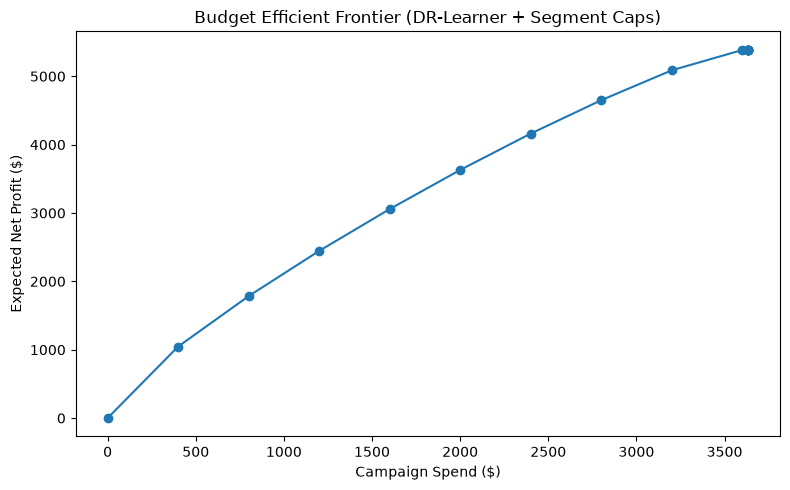

,budget,total_treated,total_cost,expected_net_profit,expected_incremental_conversions
0,0.0,0.0,0.0,0.000000,0.000000
1,400.0,800.0,400.0,1046.322495,96.421500
2,800.0,1600.0,800.0,1784.146942,172.276463
3,1200.0,2400.0,1200.0,2445.370754,243.024717
4,1600.0,3200.0,1600.0,3057.139793,310.475986
5,2000.0,4000.0,2000.0,3629.735574,375.315705
6,2400.0,4800.0,2400.0,4161.356751,437.423783
7,2800.0,5600.0,2800.0,4649.907709,496.660514
8,3200.0,6400.0,3200.0,5086.817560,552.454504
9,3600.0,7200.0,3600.0,5384.191486,598.946099


In [3]:
budgets = np.linspace(0.0, 6400.0, 17)
frontier_df = budget_frontier(
    predictions["dr_learner"],
    value=visit_value,
    cost=treatment_cost,
    budgets=budgets,
    segment_labels=test_df["channel"].to_numpy(),
    segment_caps={"Phone": 3000, "Web": 3000, "Multichannel": 1500},
    allow_fractional=True,
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(frontier_df["total_cost"], frontier_df["expected_net_profit"], marker="o")
ax.set_xlabel("Campaign Spend ($)")
ax.set_ylabel("Expected Net Profit ($)")
ax.set_title("Budget Efficient Frontier (DR-Learner + Segment Caps)")
plt.tight_layout()
plt.show()
frontier_df.head(10)

              policy  total_steps  total_treated  treat_rate  \
0             linucb         2000           1106      0.5530   
1  thompson_sampling         2000           1107      0.5535   
2      static_uplift         2000           1835      0.9175   
3             random         2000           1012      0.5060   

   cumulative_regret  cumulative_net_revenue  
0             442.10                  3512.0  
1             523.75                  3301.5  
2             924.35                  3042.5  
3             959.40                  2974.0  


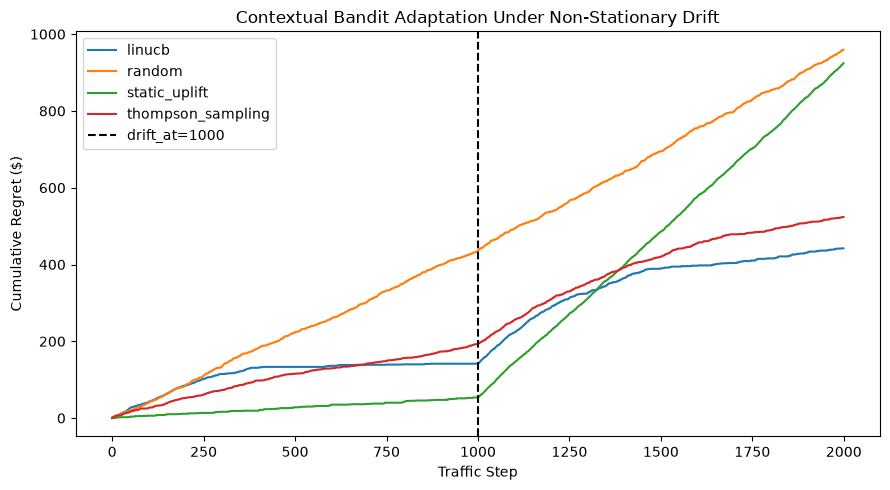

In [4]:
n_sim = 2000
X_sim = test_df.select(["recency", "history", "mens", "womens", "newbie"]).head(n_sim).to_numpy().astype(float)
X_sim = (X_sim - X_sim.mean(axis=0)) / (X_sim.std(axis=0) + 1e-8)

p0_sim = np.clip(0.11 + 0.03 * np.tanh(X_sim[:, 1]), 0.02, 0.90)
p1_sim = np.clip(p0_sim + 0.07 + 0.04 * (X_sim[:, 0] < 0), 0.02, 0.95)

sim_df = simulate_bandit_horizon(
    X=X_sim,
    probs_control=p0_sim,
    probs_treat=p1_sim,
    static_uplift_scores=predictions["dr_learner"][:n_sim],
    value=visit_value,
    cost=treatment_cost,
    drift_at=1000,
    drift_shift=-0.12,
    seed=42,
)
print(summarize_bandit_results(sim_df))

fig, ax = plt.subplots(figsize=(9, 5))
for policy, grp in sim_df.groupby("policy"):
    ax.plot(grp["step"], grp["cumulative_regret"], label=policy)
ax.axvline(1000, color="black", linestyle="--", label="drift_at=1000")
ax.set_xlabel("Traffic Step")
ax.set_ylabel("Cumulative Regret ($)")
ax.set_title("Contextual Bandit Adaptation Under Non-Stationary Drift")
ax.legend()
plt.tight_layout()
plt.show()